# Gradient Descent for Linear Regression

#### **Building gradient descent for Linear Regression step-by-step from scratch.**

- Linear Regression is a fundamental algorithm in machine learning used for predicting a continuous target variable based on one or more input features. 
- Gradient Descent is an optimization algorithm used to minimize the cost function in Linear Regression by iteratively adjusting the model parameters.

<br>

## **Gradient Descent Summary**
For a linear model that predicts $f_{w,b}(x^{(i)})$:
$$f_{w,b}(x^{(i)}) = wx^{(i)} + b \tag{1}$$

In Linear Regression, you utilize input training data to fit the parameters $w$,$b$ by minimizing a measure of the error between our predictions $f_{w,b}(x^{(i)})$ and the actual data $y^{(i)}$. The measure is called the $cost$, $J(w,b)$. In training you measure the cost over all of our training samples $x^{(i)},y^{(i)}$
$$J(w,b) = \frac{1}{2m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})^2\tag{2}$$

Gradient Descent algorithm is described as:

$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline
\;  w &= w -  \alpha \frac{\partial J(w,b)}{\partial w} \tag{3}  \; \newline 
 b &= b -  \alpha \frac{\partial J(w,b)}{\partial b}  \newline \rbrace
\end{align*}$$
where, parameters $w$, $b$ are updated simultaneously.  
The gradient is defined as:
$$
\begin{align}
\frac{\partial J(w,b)}{\partial w}  &= \frac{1}{m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)} \tag{4}\\
  \frac{\partial J(w,b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)}) \tag{5}\\
\end{align}
$$

Here *simultaniously* means that you calculate the partial derivatives for all the parameters before updating any of the parameters.

<br>

## **Implement Gradient Descent**
You will implement gradient descent algorithm for one feature. You will need three functions. 
- `compute_gradient` implementing equation (4) and (5) above
- `compute_cost` implementing equation (2) above (code from previous lab)
- `gradient_descent`, utilizing compute_gradient and compute_cost

Conventions:
- The naming of python variables containing partial derivatives follows this pattern,$\frac{\partial J(w,b)}{\partial b}$  will be `dj_db`.
- w.r.t is With Respect To, as in partial derivative of $J(wb)$ With Respect To $b$.


In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load our data set (Sample data set with one feature and one target variable)
x_train = np.array([1.0, 2.0])   #features
y_train = np.array([300.0, 500.0])   #target value

### **Cost function**

`compute_cost` computes the cost function $J(w,b)$ for linear regression. The cost function is a measure of how well the model's predictions match the actual data. It calculates the average squared difference between the predicted values and the actual target values.

In [3]:
def compute_cost(x, y, w, b):
    
    m = x.shape[0]  # number of training examples
    cost = 0

    for i in range(m):
        f_wb = w * x[i] + b
        cost += (f_wb - y[i])**2

    total_cost = cost / (2 * m)

    return total_cost

### **Gradient function**

`compute_gradient`  implements (4) and (5) above and returns $\frac{\partial J(w,b)}{\partial w}$,$\frac{\partial J(w,b)}{\partial b}$. The embedded comments describe the operations.

In [4]:
def compute_gradient(x, y, w, b):

    # Computes the gradient for linear regression

    m = x.shape[0]
    dj_dw = 0
    dj_db = 0

    for i in range(m):
        f_wb = m * x[i] + b

        dj_dw_i = (f_wb - y[i]) * x[i]
        dj_db_i = f_wb - y[i]

        dj_dw += dj_dw_i
        dj_db += dj_db_i

    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

### **Gradient Descent**

Now that gradients can be computed,  gradient descent, described in equation (3) above can be implemented below in `gradient_descent`. The details of the implementation are described in the comments. Below, you will utilize this function to find optimal values of $w$ and $b$ on the training data.

In [5]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function):

    ''' Performs gradient descent to fit w,b. Updates w,b by taking 
    num_iters gradient steps with learning rate alpha. '''

    J_history = []
    p_history = []
    w = w_in
    b = b_in

    for i in range(num_iters):
        # Claculate the gradients and update the parameters using gradient_funcion
        dj_dw, dj_db = gradient_function(x, y, w, b)

        # Update paramenters
        w = w - (alpha * dj_dw)
        b = b - (alpha * dj_db)

        # Save cost function J at each iteration
        if i<100000:
            J_history.append( cost_function(x, y, w , b))
            p_history.append([w,b])

        # Print cost every at intervals 10 times or as many iterations if < 10
        if i% math.ceil(num_iters/10) == 0:
            print(f"Iteration {i:4}: Cost {J_history[-1]:0.2e} ",
                  f"dj_dw: {dj_dw: 0.3e}, dj_db: {dj_db: 0.3e}  ",
                  f"w: {w: 0.3e}, b:{b: 0.5e}")
    
    return w, b, J_history, p_history

In [6]:
# initialize parameters
w_init = 0
b_init = 0

# some gradient descent settings
iterations = 10000
tmp_alpha = 1.0e-2

# run gradient descent
w_final, b_final, J_hist, p_hist = gradient_descent(x_train ,y_train, w_init, b_init, tmp_alpha, 
                                                    iterations, compute_cost, compute_gradient)

print(f"(w,b) found by gradient descent: ({w_final:8.4f},{b_final:8.4f})")

Iteration    0: Cost 7.93e+04  dj_dw: -6.450e+02, dj_db: -3.970e+02   w:  6.450e+00, b: 3.97000e+00
Iteration 1000: Cost 1.43e+06  dj_dw: -4.953e+01, dj_db: -1.714e-02   w:  1.091e+03, b: 3.96983e+02
Iteration 2000: Cost 3.06e+06  dj_dw: -4.950e+01, dj_db: -7.399e-07   w:  1.586e+03, b: 3.97000e+02
Iteration 3000: Cost 5.30e+06  dj_dw: -4.950e+01, dj_db: -3.195e-11   w:  2.081e+03, b: 3.97000e+02
Iteration 4000: Cost 8.16e+06  dj_dw: -4.950e+01, dj_db: -2.842e-12   w:  2.576e+03, b: 3.97000e+02
Iteration 5000: Cost 1.16e+07  dj_dw: -4.950e+01, dj_db: -2.842e-12   w:  3.071e+03, b: 3.97000e+02
Iteration 6000: Cost 1.57e+07  dj_dw: -4.950e+01, dj_db: -2.842e-12   w:  3.566e+03, b: 3.97000e+02
Iteration 7000: Cost 2.04e+07  dj_dw: -4.950e+01, dj_db: -2.842e-12   w:  4.061e+03, b: 3.97000e+02
Iteration 8000: Cost 2.57e+07  dj_dw: -4.950e+01, dj_db: -2.842e-12   w:  4.556e+03, b: 3.97000e+02
Iteration 9000: Cost 3.16e+07  dj_dw: -4.950e+01, dj_db: -2.842e-12   w:  5.051e+03, b: 3.97000e+02


### **Cost versus iterations of gradient descent**

A plot of cost versus iterations is a useful measure of progress in gradient descent. Cost should always decrease in successful runs. The change in cost is so rapid initially, it is useful to plot the initial decent on a different scale than the final descent. In the plots below, note the scale of cost on the axes and the iteration step.

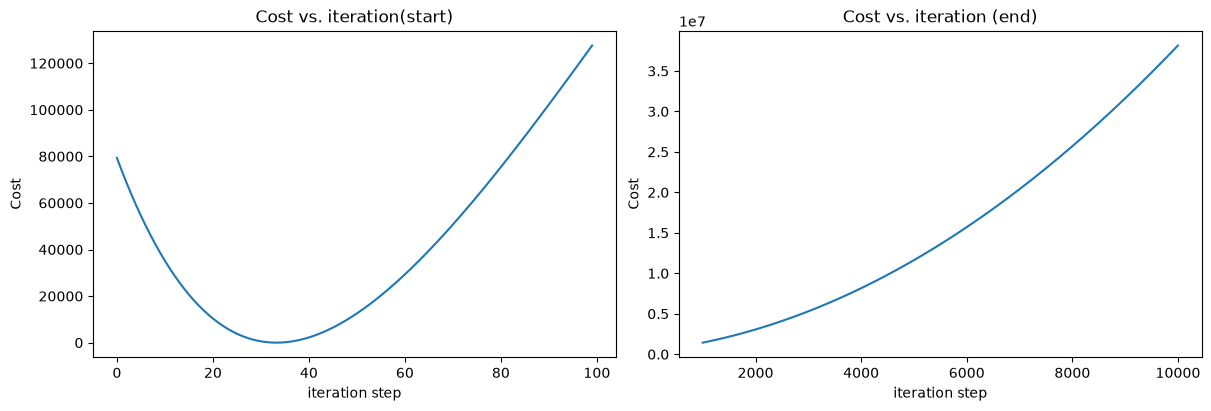

In [7]:
# plot cost versus iteration  
fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(12,4))
ax1.plot(J_hist[:100])
ax2.plot(1000 + np.arange(len(J_hist[1000:])), J_hist[1000:])
ax1.set_title("Cost vs. iteration(start)");  ax2.set_title("Cost vs. iteration (end)")
ax1.set_ylabel('Cost')            ;  ax2.set_ylabel('Cost') 
ax1.set_xlabel('iteration step')  ;  ax2.set_xlabel('iteration step') 
plt.show()

### **Predictions**

Now that you have discovered the optimal values for the parameters $w$ and $b$, you can now use the model to predict housing values based on our learned parameters. As expected, the predicted values are nearly the same as the training values for the same housing. Further, the value not in the prediction is in line with the expected value.

In [8]:
print(f"1000 sqft house prediction {w_final*1.0 + b_final:0.1f} Thousand dollars")
print(f"1200 sqft house prediction {w_final*1.2 + b_final:0.1f} Thousand dollars")
print(f"2000 sqft house prediction {w_final*2.0 + b_final:0.1f} Thousand dollars")

1000 sqft house prediction 5942.5 Thousand dollars
1200 sqft house prediction 7051.6 Thousand dollars
2000 sqft house prediction 11488.0 Thousand dollars
